# Week 4: Supervised Learning Model Implementation

## Predicting Bank Term Deposit Subscription Using Supervised Machine Learning

**Internship:** YUVA Virtual Data Science with Python  
**Task:** Week 4 – Supervised Learning Model Implementation  
**Dataset:** UCI Bank Marketing Dataset  
**Models:** Logistic Regression and Random Forest Classifier

## 1. Import Required Libraries

The following Python libraries are used for data manipulation, visualization, preprocessing, model development, validation, and performance evaluation.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All required libraries imported successfully.")

All required libraries imported successfully.


## 2. Load the Dataset

The UCI Bank Marketing dataset contains information about customers contacted during a bank's marketing campaign. The target variable `y` indicates whether the customer subscribed to a term deposit.

The `bank-full.csv` dataset is used for this project.

In [2]:
data_path = "data/bank-full.csv"

df = pd.read_csv(data_path, sep=";")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully.
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 3. Dataset Overview

The dataset is examined to understand its dimensions, column names, data types, and general structure before preprocessing.

In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst five records:")
display(df.head())

Number of rows: 45211
Number of columns: 17

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Data types:
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

First five records:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 4. Statistical Summary

Descriptive statistics are calculated for the numerical variables to understand their central tendency, spread, and range.

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


## 5. Data Quality Check

The dataset is checked for missing values and duplicate records before model development.

In [5]:
missing_values = df.isnull().sum()
duplicate_count = df.duplicated().sum()

print("Missing values:")
print(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", duplicate_count)

Missing values:
Series([], dtype: int64)

Total missing values: 0
Duplicate rows: 0


## 6. Target Variable Analysis

The target variable `y` represents whether a customer subscribed to a term deposit. Its class distribution is examined to understand the balance between positive and negative outcomes.

y
no     39922
yes     5289
Name: count, dtype: int64

Target percentages:
y
no     88.3
yes    11.7
Name: count, dtype: float64


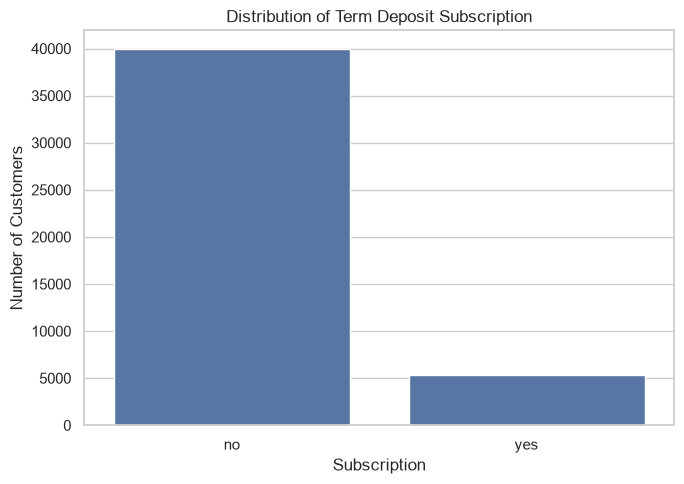

In [6]:
target_counts = df["y"].value_counts()

print(target_counts)
print("\nTarget percentages:")
print((target_counts / len(df) * 100).round(2))

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="y")
plt.title("Distribution of Term Deposit Subscription")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## 7. Exploratory Feature Analysis

Important numerical and categorical variables are visualized to understand their relationship with customer characteristics and the target variable.

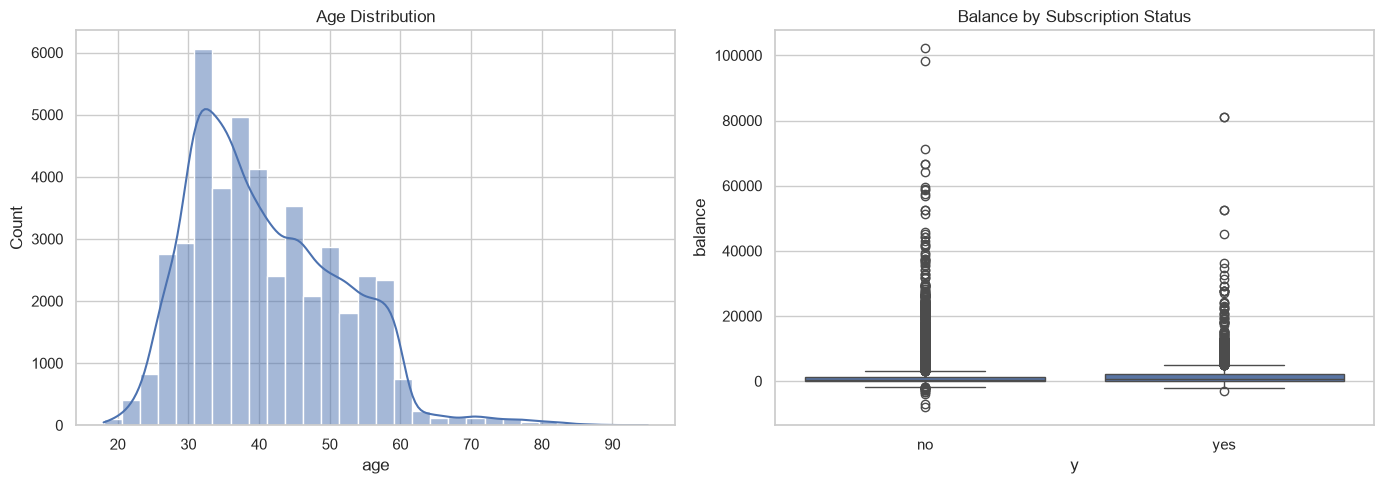

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x="age", bins=30, kde=True, ax=axes[0])
axes[0].set_title("Age Distribution")

sns.boxplot(data=df, x="y", y="balance", ax=axes[1])
axes[1].set_title("Balance by Subscription Status")

plt.tight_layout()
plt.show()

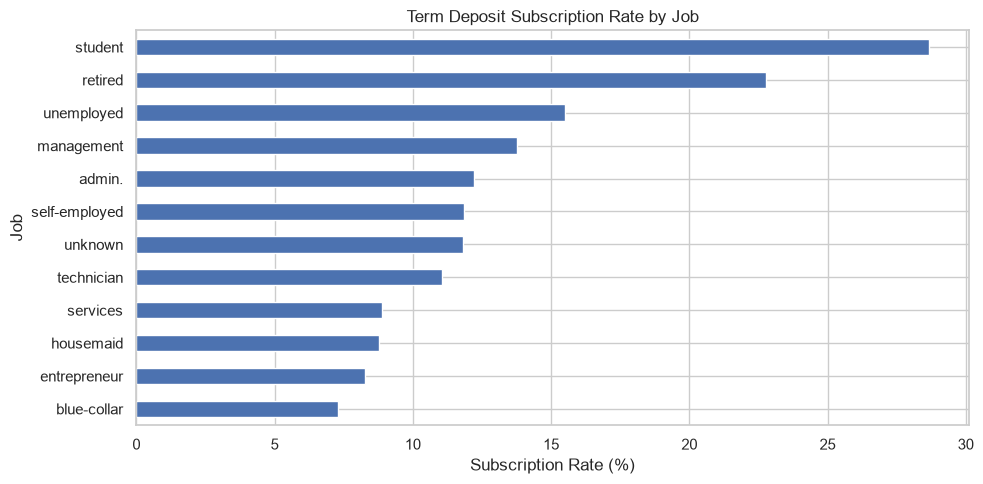

In [8]:
plt.figure(figsize=(10, 5))

job_subscription = pd.crosstab(
    df["job"],
    df["y"],
    normalize="index"
) * 100

job_subscription["yes"].sort_values().plot(kind="barh")

plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job")
plt.tight_layout()
plt.show()

## 8. Feature Engineering

Additional features are created from existing variables to improve the representation of customer information.

The following transformations are performed:

- `age_group`: groups customers into meaningful age categories.
- `balance_category`: categorizes account balance.
- `previous_contact`: indicates whether the customer had been contacted previously.
- `pdays` is retained as an input feature, while its special value of `-1` is handled through the derived previous-contact indicator.

The `duration` variable is excluded because it represents the duration of the current contact and is only known after the interaction has taken place. Including it could introduce information leakage for a realistic pre-contact prediction task.

In [9]:
model_df = df.copy()

# Age groups
model_df["age_group"] = pd.cut(
    model_df["age"],
    bins=[0, 25, 35, 50, 65, 100],
    labels=["Young", "Adult", "Middle_Aged", "Senior", "Elderly"]
)

# Balance categories
model_df["balance_category"] = pd.cut(
    model_df["balance"],
    bins=[-np.inf, 0, 1000, 5000, np.inf],
    labels=["Negative_or_Zero", "Low", "Medium", "High"]
)

# Previous contact indicator
model_df["previous_contact"] = np.where(
    model_df["pdays"] == -1,
    "No",
    "Yes"
)

# Remove duration to avoid information leakage
model_df = model_df.drop(columns=["duration"])

print("Feature engineering completed.")
print("\nNew features:")
print(["age_group", "balance_category", "previous_contact"])

print("\nNew dataset shape:", model_df.shape)

model_df.head()

Feature engineering completed.

New features:
['age_group', 'balance_category', 'previous_contact']

New dataset shape: (45211, 19)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y,age_group,balance_category,previous_contact
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown,no,Senior,Medium,No
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown,no,Middle_Aged,Low,No
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown,no,Adult,Low,No
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,1,-1,0,unknown,no,Middle_Aged,Medium,No
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,-1,0,unknown,no,Adult,Low,No


## 9. Feature and Target Separation

The target variable `y` is separated from the input features. The target is converted into binary numerical form where `yes = 1` and `no = 0`.

In [10]:
X = model_df.drop(columns=["y"])
y = model_df["y"].map({"no": 0, "yes": 1})

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

Feature shape: (45211, 18)
Target shape: (45211,)

Target values:
y
0    39922
1     5289
Name: count, dtype: int64


In [11]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'age_group', 'balance_category', 'previous_contact']

Number of numerical features: 6
Number of categorical features: 12


## 10. Train-Test Split

The dataset is divided into training and testing subsets. A stratified split is used so that the proportion of positive and negative target classes remains similar in both subsets.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training set: (36168, 18)
Testing set: (9043, 18)

Training target distribution:
y
0    0.883
1    0.117
Name: proportion, dtype: float64

Testing target distribution:
y
0    0.883
1    0.117
Name: proportion, dtype: float64


## 11. Preprocessing Pipeline

Numerical features are standardized using StandardScaler, while categorical features are converted into numerical form using One-Hot Encoding.

A ColumnTransformer is used so that preprocessing is applied consistently during both training and prediction.

In [13]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 12. Logistic Regression Model

Logistic Regression is implemented as the baseline supervised classification model. It is suitable for binary classification and provides an interpretable baseline against which the more flexible Random Forest model can be compared.

In [14]:
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

logistic_pipeline.fit(X_train, y_train)

logistic_predictions = logistic_pipeline.predict(X_test)
logistic_probabilities = logistic_pipeline.predict_proba(X_test)[:, 1]

print("Logistic Regression training completed.")

Logistic Regression training completed.


## 13. Random Forest Classifier

Random Forest is implemented as the second supervised learning model. It combines multiple decision trees and can model nonlinear relationships between customer characteristics and the target variable.

In [15]:
random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            max_depth=12,
            min_samples_split=10,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest_pipeline.fit(X_train, y_train)

rf_predictions = random_forest_pipeline.predict(X_test)
rf_probabilities = random_forest_pipeline.predict_proba(X_test)[:, 1]

print("Random Forest training completed.")

Random Forest training completed.


## 14. Model Evaluation

Both models are evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.

These metrics provide a broader assessment than accuracy alone, which is important because the target classes are not evenly distributed.

In [16]:
def evaluate_model(name, y_true, predictions, probabilities):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1-Score": f1_score(y_true, predictions),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

logistic_results = evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_predictions,
    logistic_probabilities
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_predictions,
    rf_probabilities
)

results_df = pd.DataFrame([logistic_results, rf_results])

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7671,0.2820,0.6408,0.3917,0.7779
1,Random Forest,0.8203,0.3491,0.6200,0.4467,0.7978


## 15. 5-Fold Cross-Validation

Stratified 5-fold cross-validation is performed to evaluate how consistently each model performs across different subsets of the training data.

Accuracy, precision, recall, F1-score, and ROC-AUC are measured for each fold.

In [17]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

logistic_cv = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

rf_cv = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

cv_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Logistic Regression": [
        logistic_cv["test_accuracy"].mean(),
        logistic_cv["test_precision"].mean(),
        logistic_cv["test_recall"].mean(),
        logistic_cv["test_f1"].mean(),
        logistic_cv["test_roc_auc"].mean()
    ],
    "Random Forest": [
        rf_cv["test_accuracy"].mean(),
        rf_cv["test_precision"].mean(),
        rf_cv["test_recall"].mean(),
        rf_cv["test_f1"].mean(),
        rf_cv["test_roc_auc"].mean()
    ]
})

cv_results.round(4)

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.7635,0.8196
1,Precision,0.2753,0.3436
2,Recall,0.6249,0.5911
3,F1-Score,0.3821,0.4343
4,ROC-AUC,0.7684,0.7893


## 16. Confusion Matrix Analysis

Confusion matrices are used to examine true positives, true negatives, false positives, and false negatives produced by each classifier.

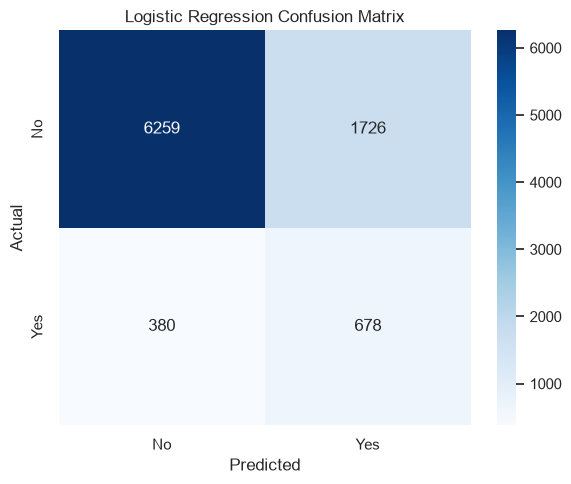

In [18]:
cm_logistic = confusion_matrix(y_test, logistic_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

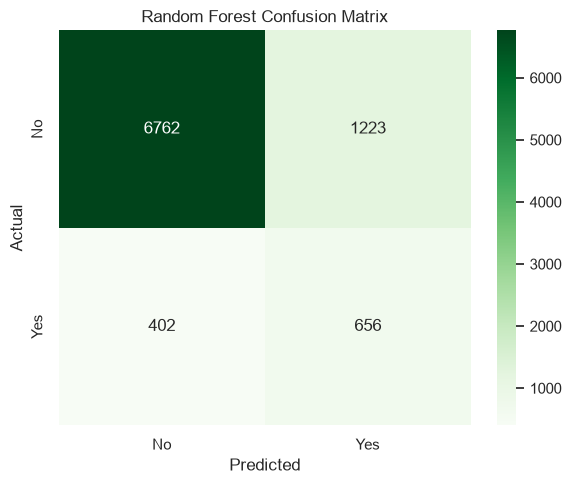

In [19]:
cm_rf = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [20]:
print("LOGISTIC REGRESSION")
print("=" * 60)
print(classification_report(
    y_test,
    logistic_predictions,
    target_names=["No Subscription", "Subscription"]
))

print("\nRANDOM FOREST")
print("=" * 60)
print(classification_report(
    y_test,
    rf_predictions,
    target_names=["No Subscription", "Subscription"]
))

LOGISTIC REGRESSION
                 precision    recall  f1-score   support

No Subscription       0.94      0.78      0.86      7985
   Subscription       0.28      0.64      0.39      1058

       accuracy                           0.77      9043
      macro avg       0.61      0.71      0.62      9043
   weighted avg       0.87      0.77      0.80      9043


RANDOM FOREST
                 precision    recall  f1-score   support

No Subscription       0.94      0.85      0.89      7985
   Subscription       0.35      0.62      0.45      1058

       accuracy                           0.82      9043
      macro avg       0.65      0.73      0.67      9043
   weighted avg       0.87      0.82      0.84      9043



## 17. Model Performance Comparison

The performance of Logistic Regression and Random Forest is compared across multiple evaluation metrics.

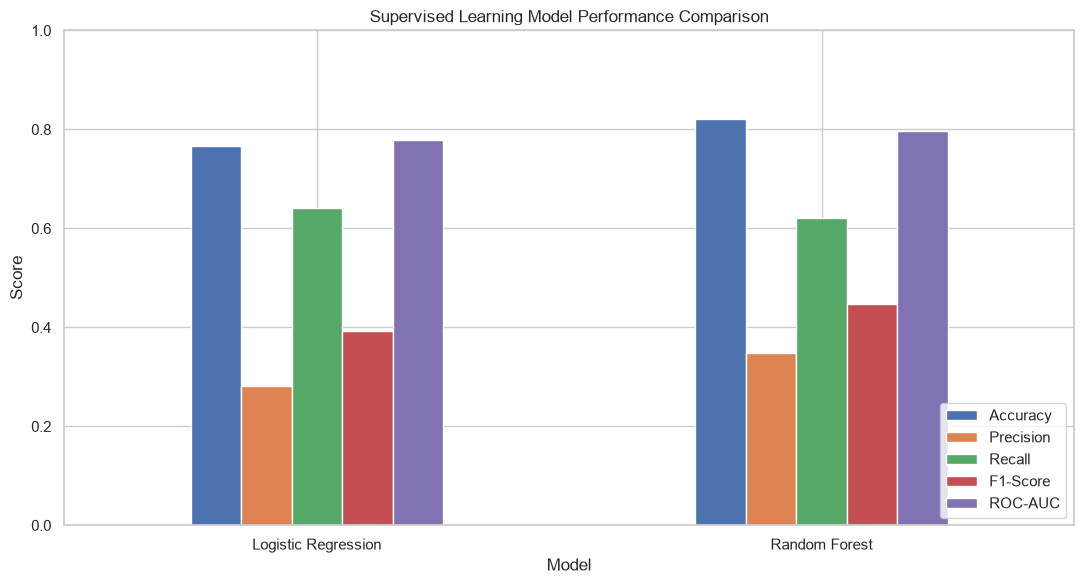

In [21]:
comparison = results_df.set_index("Model")

comparison.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Supervised Learning Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 18. ROC Curve Analysis

ROC curves are plotted for both models to compare their ability to distinguish between customers who subscribed and those who did not.

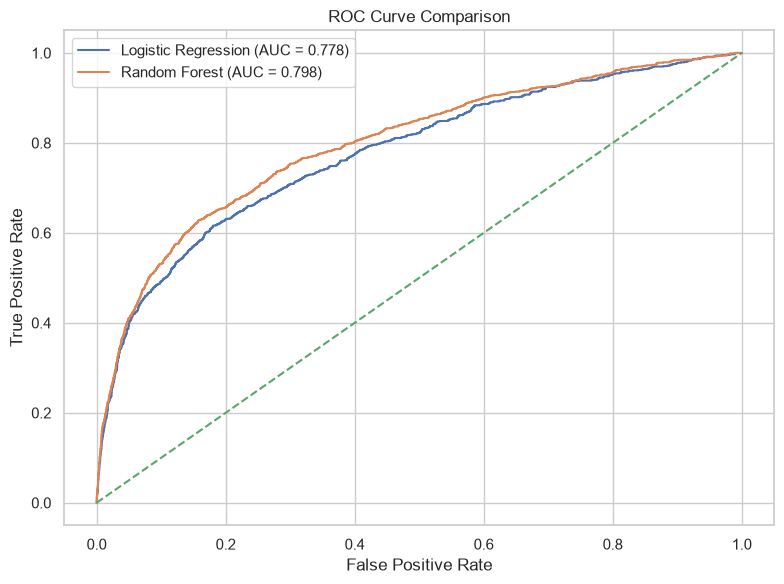

In [22]:
logistic_fpr, logistic_tpr, _ = roc_curve(
    y_test,
    logistic_probabilities
)

rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    logistic_fpr,
    logistic_tpr,
    label=f"Logistic Regression (AUC = {roc_auc_score(y_test, logistic_probabilities):.3f})"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {roc_auc_score(y_test, rf_probabilities):.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

## 19. Feature Importance Analysis

Random Forest provides feature importance values that can be used to identify which transformed input variables contributed most strongly to the model's predictions.

Top 15 important features:


,Feature,Importance
48,cat__poutcome_success,0.092615
33,cat__contact_unknown,0.072724
0,num__age,0.063336
4,num__pdays,0.058170
1,num__balance,0.056721
2,num__day,0.049858
28,cat__housing_yes,0.049223
31,cat__contact_cellular,0.042410
27,cat__housing_no,0.040107
5,num__previous,0.032710


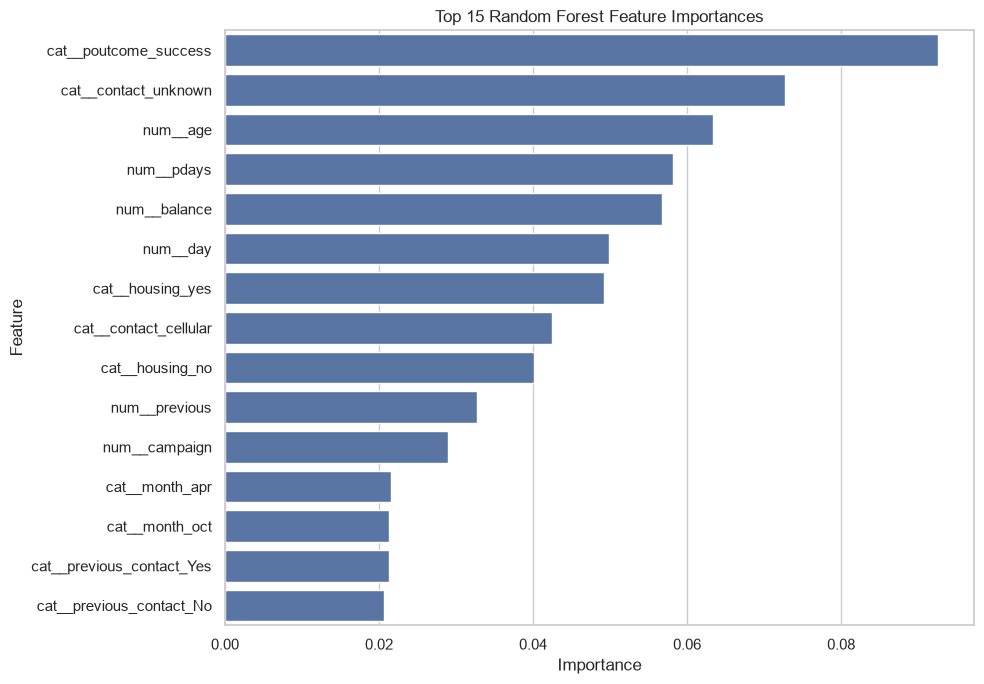

In [23]:
rf_preprocessor = random_forest_pipeline.named_steps["preprocessor"]
rf_model = random_forest_pipeline.named_steps["model"]

feature_names = rf_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).head(15)

print("Top 15 important features:")
display(importance_df)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Random Forest Feature Importances")
plt.tight_layout()
plt.show()

## 20. Save Model Outputs

Predictions and evaluation results are saved as CSV files so that the outputs can be reused in the project report and GitHub repository.

In [24]:
os.makedirs("output", exist_ok=True)

predictions_df = X_test.copy()
predictions_df["Actual"] = y_test.values
predictions_df["Logistic_Prediction"] = logistic_predictions
predictions_df["Random_Forest_Prediction"] = rf_predictions

predictions_df.to_csv(
    "output/model_predictions.csv",
    index=False
)

results_df.to_csv(
    "output/model_metrics.csv",
    index=False
)

cv_results.to_csv(
    "output/cross_validation_results.csv",
    index=False
)

importance_df.to_csv(
    "output/feature_importance.csv",
    index=False
)

print("All model outputs saved successfully.")

All model outputs saved successfully.


## 21. Final Validation

The final project is validated by checking dataset dimensions, missing values, duplicate records, target distribution, model availability, and saved output files.

In [25]:
print("FINAL VALIDATION")
print("=" * 60)

print("Original dataset shape:", df.shape)
print("Model dataset shape:", model_df.shape)

print("Missing values:", model_df.isnull().sum().sum())
print("Duplicate rows:", model_df.duplicated().sum())

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTarget classes:")
print(y.value_counts())

print("\nModels trained:")
print("1. Logistic Regression")
print("2. Random Forest Classifier")

print("\nOutput files:")
print(os.listdir("output"))

print("\nFinal validation completed successfully.")

FINAL VALIDATION
Original dataset shape: (45211, 17)
Model dataset shape: (45211, 19)
Missing values: 0
Duplicate rows: 16

Training samples: 36168
Testing samples: 9043

Target classes:
y
0    39922
1     5289
Name: count, dtype: int64

Models trained:
1. Logistic Regression
2. Random Forest Classifier

Output files:
['cross_validation_results.csv', 'feature_importance.csv', 'model_metrics.csv', 'model_predictions.csv']

Final validation completed successfully.


## 22. Conclusion

This project implemented a complete supervised learning workflow for predicting whether bank customers would subscribe to a term deposit. The process included data exploration, quality checking, feature engineering, preprocessing, stratified train-test splitting, model training, cross-validation, and evaluation.

Logistic Regression was used as an interpretable baseline, while Random Forest was used to capture potentially nonlinear relationships in the data. Multiple evaluation metrics, including accuracy, precision, recall, F1-score, and ROC-AUC, were used instead of relying on accuracy alone.

The `duration` variable was excluded because it represents information available after the customer interaction and could introduce information leakage in a pre-contact prediction scenario. Additional engineered features such as age groups, balance categories, and previous-contact status were incorporated into the modeling pipeline.

The final analysis provides a comparison of the two models, their validation performance, confusion matrices, ROC curves, and feature importance. The results demonstrate how supervised machine learning can be applied to a real-world marketing prediction problem while considering data preparation, validation, interpretability, and practical limitations.